&nbsp;

&nbsp;

# HN-score transcript - fanta.bio CRE pair Visualization

In [1]:
import os
import datetime
import pathlib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import polars as pl
import matplotlib.pyplot as plt
from upsetplot import UpSet, from_contents
from IPython.display import display


os.environ["POLARS_MAX_THREADS"] = "16"

In [2]:
VERSION = datetime.datetime.now().strftime("%y%m")
Execute_date = datetime.datetime.now().strftime("%y%m%d")
print(f"Execute Date: {Execute_date}")

Execute Date: 261021


&nbsp;

&nbsp;

&nbsp;

## 0. All HN-score calculated Transcript - CRE pairs

- 公共遺伝子発現データ (bulk RNA-seq) のメタ解析 によって得られた transcriptsのデータを使用する
- このデータには、CRE と対応づいていない transcript も含まれていることに注意
- [./02_1_HNscore_transcript_fantabio.ipynb](./02_1_HNscore_transcript_fantabio.ipynb) によって作成した対応表を使用する

In [3]:
HNscore_transcript_all_fantabio = pl.read_parquet(
    f"../../out/fantabio/parquet_file/HNscore_transcript_all_fantabio_v261001.parquet"
)

pl.Config.set_tbl_rows(4)
display(HNscore_transcript_all_fantabio)

transcript_id,UP2,DOWN2,UNCHANGED2,HN2,UP2_stranded,DOWN2_stranded,UNCHANGED2_stranded,HN2_stranded,gene_symbol,HGNC_ID,transcript_type,gene_id,tags,strand,number_of_tags,RNACentral_ID,corrrespondence,polyA_features,gene_source,annotation_remarks,annotation_remark_count,cre_id,cre_chrom,cre_chrom_start,cre_chrom_end,cre_name,tss_nearest_transcript_ids,tss_nearest_transcript_distance,transcript_distance,screen_ccres,chip_atlas_antigens,silencerdbs,fantom5_cage_peaks,fantom5_enhancers,directionality,fantabio_cre_class,itemRgb,itemRgb_name
str,i64,i64,i64,i64,i64,i64,i64,i64,str,str,str,str,list[str],str,u32,str,str,list[str],str,list[str],u32,str,str,i64,str,str,list[str],str,i64,list[struct[2]],list[struct[3]],list[struct[5]],list[struct[2]],list[struct[1]],f64,str,str,str
"""ENST00000309758.6""",352,17,37,335,232,4,15,228,"""HSPA6""","""HGNC:5239""","""protein_coding""","""ENSG00000173110.8""","[""basic"", ""Ensembl_canonical"", … ""CCDS""]","""+""",6,null,null,null,"""ensembl_havana_gene_homo_sapie…","[""MANE_select""]",1,"""FCHS_28105""","""chr1""",161523745,"""161524487""","""cp1@HSPA6""","[""GQ891451""]","""0""",53,"[{""EH38E2843853"",""pELS""}, {""EH38E2843855"",""PLS""}, {""EH38E3981533"",""pELS""}]","[{""STAG2"",4103,[{""SRX9975614"",4103}, {""SRX9975613"",3500}, {""SRX26159208"",562}]}, {""HSF1"",4038,[{""SRX16646095"",4038}, {""SRX16646111"",3572}, … {""SRX13845684"",554}]}, … {""GABPA"",500,[{""SRX2635792"",500}]}]","[{""HS_00013400"",""H1 BMP4 Derived Mesendoderm Cultured Cells"",""Mesendoderm cell"",""Others"",""SVM""}, {""HS_00013401"",""H1 Cells"",""Embryonic stem cell"",""Stem cell"",""SVM""}, … {""HS_00013403"",""Foreskin Fibroblast Primary Cells skin02"",""Prepuce"",""Skin"",""SVM""}]",null,null,0.982111,"""PLA""","""204,0,0""","""red"""
"""ENST00000309758.6""",352,17,37,335,232,4,15,228,"""HSPA6""","""HGNC:5239""","""protein_coding""","""ENSG00000173110.8""","[""basic"", ""Ensembl_canonical"", … ""CCDS""]","""+""",6,null,null,null,"""ensembl_havana_gene_homo_sapie…","[""MANE_select""]",1,"""FCHS_28106""","""chr1""",161524161,"""161524546""","""cp4@HSPA6""","[""ENST00000309758.6"", ""NM_002155.5"", … ""AK295212""]","""0""",0,"[{""EH38E2843855"",""PLS""}]","[{""HSF1"",4038,[{""SRX16646095"",4038}, {""SRX16646111"",3572}, … {""SRX3322007"",560}]}, {""CTCF"",3651,[{""SRX10975999"",3651}, {""SRX10976007"",2920}, … {""SRX13551280"",511}]}, … {""MED12"",511,[{""SRX10852993"",511}]}]","[{""HS_00013400"",""H1 BMP4 Derived Mesendoderm Cultured Cells"",""Mesendoderm cell"",""Others"",""SVM""}, {""HS_00013401"",""H1 Cells"",""Embryonic stem cell"",""Stem cell"",""SVM""}, … {""HS_00013403"",""Foreskin Fibroblast Primary Cells skin02"",""Prepuce"",""Skin"",""SVM""}]","[{""hg19::chr1:161494328..161494332,+;hg_6264.1"",""p1@HSPA6""}]",null,0.943234,"""PLA""","""204,0,0""","""red"""
…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…
"""ENST00000549545.1""",11,265,130,-254,8,174,69,-166,"""COQ10A""","""HGNC:26515""","""retained_intron""","""ENSG00000135469.15""",[],"""+""",0,null,null,null,"""ensembl_havana_gene_homo_sapie…",null,0,"""FCHS_96252""","""chr12""",56268140,"""56268446""","""cp6@COQ10A""","[""ENST00000549545.1""]","""-23""",-23,"[{""EH38E4064794"",""pELS""}]",null,"[{""HS_00173371"",""H1 BMP4 Derived Mesendoderm Cultured Cells"",""Mesendoderm cell"",""Others"",""SVM""}, {""HS_02053667"",""Thyroid Gland"",""Thyroid gland"",""Others"",""gkmSVM""}]",null,null,-0.368421,"""ELA""","""255,202,74""","""yellow"""
"""ENST00000560179.2""",11,272,123,-261,5,181,65,-176,"""ETFA""","""HGNC:3481""","""retained_intron""","""ENSG00000140374.18""","[""RNA_Seq_supported_partial""]","""-""",1,null,null,null,"""ensembl_havana_gene_homo_sapie…","[""RNA-Seq supported partial""]",1,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null


&nbsp;

&nbsp;

&nbsp;

&nbsp;

## 1. up5p transcript - CRE pairs

In [5]:
up5p_transcript_cre_pairs = pl.read_parquet(
    "../../out/fantabio/parquet_file/up5p_transcript_fantabio_v261001.parquet"
)

print(f"up5p_transcript - CRE pairs count: {up5p_transcript_cre_pairs.select(['transcript_id', 'cre_id']).n_unique()}")
print(f"up5p_transcript - CRE pairs count (only lncRNA): {up5p_transcript_cre_pairs.filter((pl.col('transcript_type') == 'lncRNA')).select(['transcript_id', 'cre_id']).n_unique()}")
print(f"up5p_transcripts (has fanta.bio CRE annotation): {up5p_transcript_cre_pairs.select('transcript_id').n_unique()}")
print(f"up5p lncRNA transcripts (has fanta.bio CRE annotation): {up5p_transcript_cre_pairs.filter(pl.col('transcript_type') == 'lncRNA').select('transcript_id').n_unique()}")
print(f"CREs (has fanta.bio transcript annotation): {up5p_transcript_cre_pairs.select('cre_id').n_unique()}")
print(f"CREs (PLA class): {up5p_transcript_cre_pairs.filter(pl.col('fantabio_cre_class') == 'PLA').select('cre_id').n_unique()}")
print(f"CREs (ELA class): {up5p_transcript_cre_pairs.filter(pl.col('fantabio_cre_class') == 'ELA').select('cre_id').n_unique()}")
display(up5p_transcript_cre_pairs)

up5p_transcript - CRE pairs count: 63099
up5p_transcript - CRE pairs count (only lncRNA): 9221
up5p_transcripts (has fanta.bio CRE annotation): 21696
up5p lncRNA transcripts (has fanta.bio CRE annotation): 3657
CREs (has fanta.bio transcript annotation): 33961
CREs (PLA class): 14620
CREs (ELA class): 19341


transcript_id,UP2,DOWN2,UNCHANGED2,HN2,UP2_stranded,DOWN2_stranded,UNCHANGED2_stranded,HN2_stranded,gene_symbol,HGNC_ID,transcript_type,gene_id,tags,strand,number_of_tags,RNACentral_ID,corrrespondence,polyA_features,gene_source,annotation_remarks,annotation_remark_count,cre_id,cre_chrom,cre_chrom_start,cre_chrom_end,cre_name,tss_nearest_transcript_ids,tss_nearest_transcript_distance,transcript_distance,screen_ccres,chip_atlas_antigens,silencerdbs,fantom5_cage_peaks,fantom5_enhancers,directionality,fantabio_cre_class,itemRgb,itemRgb_name
str,i64,i64,i64,i64,i64,i64,i64,i64,str,str,str,str,list[str],str,u32,str,str,list[str],str,list[str],u32,str,str,i64,str,str,list[str],str,i64,list[struct[2]],list[struct[3]],list[struct[5]],list[struct[2]],list[struct[1]],f64,str,str,str
"""ENST00000309758.6""",352,17,37,335,232,4,15,228,"""HSPA6""","""HGNC:5239""","""protein_coding""","""ENSG00000173110.8""","[""basic"", ""Ensembl_canonical"", … ""CCDS""]","""+""",6,null,null,null,"""ensembl_havana_gene_homo_sapie…","[""MANE_select""]",1,"""FCHS_28105""","""chr1""",161523745,"""161524487""","""cp1@HSPA6""","[""GQ891451""]","""0""",53,"[{""EH38E2843853"",""pELS""}, {""EH38E2843855"",""PLS""}, {""EH38E3981533"",""pELS""}]","[{""STAG2"",4103,[{""SRX9975614"",4103}, {""SRX9975613"",3500}, {""SRX26159208"",562}]}, {""HSF1"",4038,[{""SRX16646095"",4038}, {""SRX16646111"",3572}, … {""SRX13845684"",554}]}, … {""GABPA"",500,[{""SRX2635792"",500}]}]","[{""HS_00013400"",""H1 BMP4 Derived Mesendoderm Cultured Cells"",""Mesendoderm cell"",""Others"",""SVM""}, {""HS_00013401"",""H1 Cells"",""Embryonic stem cell"",""Stem cell"",""SVM""}, … {""HS_00013403"",""Foreskin Fibroblast Primary Cells skin02"",""Prepuce"",""Skin"",""SVM""}]",null,null,0.982111,"""PLA""","""204,0,0""","""red"""
"""ENST00000309758.6""",352,17,37,335,232,4,15,228,"""HSPA6""","""HGNC:5239""","""protein_coding""","""ENSG00000173110.8""","[""basic"", ""Ensembl_canonical"", … ""CCDS""]","""+""",6,null,null,null,"""ensembl_havana_gene_homo_sapie…","[""MANE_select""]",1,"""FCHS_28106""","""chr1""",161524161,"""161524546""","""cp4@HSPA6""","[""ENST00000309758.6"", ""NM_002155.5"", … ""AK295212""]","""0""",0,"[{""EH38E2843855"",""PLS""}]","[{""HSF1"",4038,[{""SRX16646095"",4038}, {""SRX16646111"",3572}, … {""SRX3322007"",560}]}, {""CTCF"",3651,[{""SRX10975999"",3651}, {""SRX10976007"",2920}, … {""SRX13551280"",511}]}, … {""MED12"",511,[{""SRX10852993"",511}]}]","[{""HS_00013400"",""H1 BMP4 Derived Mesendoderm Cultured Cells"",""Mesendoderm cell"",""Others"",""SVM""}, {""HS_00013401"",""H1 Cells"",""Embryonic stem cell"",""Stem cell"",""SVM""}, … {""HS_00013403"",""Foreskin Fibroblast Primary Cells skin02"",""Prepuce"",""Skin"",""SVM""}]","[{""hg19::chr1:161494328..161494332,+;hg_6264.1"",""p1@HSPA6""}]",null,0.943234,"""PLA""","""204,0,0""","""red"""
…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…
"""ENST00000480008.1""",114,70,222,44,53,53,145,0,"""PHF10""","""HGNC:18250""","""retained_intron""","""ENSG00000130024.16""",[],"""-""",0,null,null,"[""polya_signal"", ""polya_site""]","""ensembl_havana_gene_homo_sapie…",null,0,"""FCHS_373152""","""chr6""",169724291,"""169724957""","""cp7@PHF10""","[""ENST00000339209.9"", ""NM_018288.4"", ""NM_133325.3""]","""0""",286,"[{""EH38E3749974"",""PLS""}, {""EH38E3749975"",""pELS""}]","[{""BCORL1"",2666,[{""SRX10184498"",2666}, {""SRX10184497"",2361}, {""SRX10184496"",1707}]}, {""CTCF"",2348,[{""SRX10976007"",2348}, {""SRX10975999"",2324}, … {""SRX14609196"",549}]}, … {""SMARCA4"",500,[{""SRX9562887"",500}]}]","[{""HS_00086002"",""Gastric"",""Stomach"",""Stomach"",""SVM""}]","[{""hg19::chr6:170124563..170124616,-;hg_76798.1"",""p1@PHF10""}, {""hg19::chr6:170124805..170124830,+;hg_71276.1"",""hg_71276.1""}, … {""hg19::chr6:170124890..170124910,+;hg_71278.1"",""hg_71278.1""}]",null,-0.831798,"""PLA""","""0,0,204""","""blue"""
"""ENST00000774581.1""",101,57,248,44,34,44,173,-10,null,null,"""lncRNA""","""ENSG00000300853.1""","[""ba

&nbsp;

&nbsp;

&nbsp;

&nbsp;

## 2. down5p transcript - CRE pairs

- related notebook: [../01_HNscore/01_2_HNscore_transcript_gencode.ipynb](../01_HNscore/01_2_HNscore_transcript_gencode.ipynb)
- 収集した全ての bulk RNA-seq から計算した HN-score のデータから選抜したデータを使用する

In [6]:
down5p_transcript_cre_pairs = pl.read_parquet(
    "../../out/fantabio/parquet_file/bottom5p_transcript_fantabio_v261001.parquet"
)

print(f"down5p_transcript - CRE pairs count: {down5p_transcript_cre_pairs.select(['transcript_id', 'cre_id']).n_unique()}")
print(f"down5p_transcripts (has fanta.bio CRE annotation): {down5p_transcript_cre_pairs.select('transcript_id').n_unique()}")
print(f"down5p lncRNA transcripts (has fanta.bio CRE annotation): {down5p_transcript_cre_pairs.filter(pl.col('transcript_type') == 'lncRNA').select('transcript_id').n_unique()}")
print(f"CREs (has fanta.bio transcript annotation): {down5p_transcript_cre_pairs.select('cre_id').n_unique()}")
print(f"CREs (PLA class): {down5p_transcript_cre_pairs.filter(pl.col('fantabio_cre_class') == 'PLA').select('cre_id').n_unique()}")
print(f"CREs (ELA class): {down5p_transcript_cre_pairs.filter(pl.col('fantabio_cre_class') == 'ELA').select('cre_id').n_unique()}")
display(down5p_transcript_cre_pairs)

down5p_transcript - CRE pairs count: 66960
down5p_transcripts (has fanta.bio CRE annotation): 22185
down5p lncRNA transcripts (has fanta.bio CRE annotation): 2653
CREs (has fanta.bio transcript annotation): 34360
CREs (PLA class): 15358
CREs (ELA class): 19002


transcript_id,UP2,DOWN2,UNCHANGED2,HN2,UP2_stranded,DOWN2_stranded,UNCHANGED2_stranded,HN2_stranded,gene_symbol,HGNC_ID,transcript_type,gene_id,tags,strand,number_of_tags,RNACentral_ID,corrrespondence,polyA_features,gene_source,annotation_remarks,annotation_remark_count,cre_id,cre_chrom,cre_chrom_start,cre_chrom_end,cre_name,tss_nearest_transcript_ids,tss_nearest_transcript_distance,transcript_distance,screen_ccres,chip_atlas_antigens,silencerdbs,fantom5_cage_peaks,fantom5_enhancers,directionality,fantabio_cre_class,itemRgb,itemRgb_name
str,i64,i64,i64,i64,i64,i64,i64,i64,str,str,str,str,list[str],str,u32,str,str,list[str],str,list[str],u32,str,str,i64,str,str,list[str],str,i64,list[struct[2]],list[struct[3]],list[struct[5]],list[struct[2]],list[struct[1]],f64,str,str,str
"""ENST00000834029.1""",69,117,220,-48,47,56,148,-9,"""EXO5-DT""","""HGNC:55647""","""lncRNA""","""ENSG00000238287.2""","[""basic"", ""Ensembl_canonical"", … ""TAGENE""]","""-""",4,"""URS0002A1647B""","""ENSEMBL_GENCODE""",null,"""havana_homo_sapiens""","[""CLS3 project""]",1,"""FCHS_11684""","""chr1""",40508315,"""40508650""","""cp5@EXO5""","[""ENST00000925740.1""]","""0""",-63,"[{""EH38E2805480"",""PLS""}]","[{""ZNF687"",3399,[{""SRX10478566"",3399}, {""SRX10478565"",2503}]}, {""TCF7"",2966,[{""SRX10774913"",2966}, {""SRX10774914"",2622}]}, … {""NFATC1"",515,[{""SRX335071"",515}]}]","[{""HS_00004908"",""Foreskin Fibroblast Primary Cells skin02"",""Prepuce"",""Skin"",""SVM""}, {""HS_00004909"",""Foreskin Melanocyte Primary Cells skin01"",""Prepuce"",""Skin"",""SVM""}, … {""HS_00004912"",""Small Intestine"",""Small intestine"",""Intestine"",""SVM""}]","[{""hg19::chr1:40974317..40974346,-;hg_11928.1"",""hg_11928.1""}]",null,0.952663,"""ELA""","""255,202,74""","""yellow"""
"""ENST00000834029.1""",69,117,220,-48,47,56,148,-9,"""EXO5-DT""","""HGNC:55647""","""lncRNA""","""ENSG00000238287.2""","[""basic"", ""Ensembl_canonical"", … ""TAGENE""]","""-""",4,"""URS0002A1647B""","""ENSEMBL_GENCODE""",null,"""havana_homo_sapiens""","[""CLS3 project""]",1,"""FCHS_11685""","""chr1""",40508396,"""40508649""","""cp4@EXO5""","[""ENST00000925740.1""]","""0""",-64,"[{""EH38E2805480"",""PLS""}]","[{""ZNF143"",3836,[{""SRX1510972"",3836}, {""SRX1510970"",3469}, … {""SRX360055"",969}]}, {""ZNF687"",3399,[{""SRX10478566"",3399}, {""SRX10478565"",2503}]}, … {""PHF20"",510,[{""SRX10478496"",510}]}]","[{""HS_00004908"",""Foreskin Fibroblast Primary Cells skin02"",""Prepuce"",""Skin"",""SVM""}, {""HS_00004909"",""Foreskin Melanocyte Primary Cells skin01"",""Prepuce"",""Skin"",""SVM""}, … {""HS_00004912"",""Small Intestine"",""Small intestine"",""Intestine"",""SVM""}]","[{""hg19::chr1:40974317..40974346,-;hg_11928.1"",""hg_11928.1""}]",null,1.0,"""ELA""","""255,202,74""","""yellow"""
…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…
"""ENST00000549545.1""",11,265,130,-254,8,174,69,-166,"""COQ10A""","""HGNC:26515""","""retained_intron""","""ENSG00000135469.15""",[],"""+""",0,null,null,null,"""ensembl_havana_gene_homo_sapie…",null,0,"""FCHS_96251""","""chr12""",56267369,"""56267941""","""cp5@COQ10A""","[""ENST00000546544.5"", ""ENST00000553234.1"", … ""BC002435""]","""0""",176,"[{""EH38E1615633"",""PLS""}, {""EH38E3020442"",""PLS""}]","[{""ZNF687"",2193,[{""SRX10478566"",2193}]}, {""RXRA"",1898,[{""SRX5457233"",1898}, {""SRX5457467"",1664}, … {""SRX10475074"",813}]}, … {""USF2"",508,[{""SRX3230406"",508}]}]","[{""HS_00173371"",""H1 BMP4 Derived Mesendoderm Cultured Cells"",""Mesendoderm cell"",""Others"",""SVM""}, {""HS_03365110"",""NHEK-Epidermal Keratinocyte Primary Cells"",""Skin"",""Skin"",""DeepSilencer""}]","[{""hg19::chr12:56661400..56661422,+;hg_126102.1"",""p6@COQ10A""}, {""hg19::chr12:56661461..56661480,+;hg_126103.1"",""p5@COQ10A""}]",null,0.991374,"""PLA""","""204,0,0""","""red"""
"""ENST00000549545.1""",11,265,130,-254,8,174,69,-166,"""COQ10A""","""HGNC:26515""","""retained_intron""","""ENSG00000135469.15""",[],"""+""",0,null,null,null,"""ensembl_h

&nbsp;

&nbsp;

&nbsp;

&nbsp;

## 3. Transcript - CRE Distance Distribution Servey

&nbsp;

&nbsp;

## 3. up5p transcript-CRE distance

In [7]:
# このデータフレームの行数 = transcript - CRE pair count になる
up5p_transcript_cre_pairs = up5p_transcript_cre_pairs.select(
    "transcript_id",
    "cre_id",
    "cre_name",
    "fantabio_cre_class",
    "transcript_distance"
).with_columns(
    pl.col("transcript_distance").abs().alias("transcript_distance_abs") # Point: 絶対値に変換
).unique()


display(up5p_transcript_cre_pairs)

transcript_id,cre_id,cre_name,fantabio_cre_class,transcript_distance,transcript_distance_abs
str,str,str,str,i64,i64
"""ENST00000621033.2""","""FCHS_23375""","""cp1@LINC01145""","""PLA""",143,143
"""ENST00000898817.1""","""FCHS_439065""","""cp6@FTSJ1""","""ELA""",72,72
…,…,…,…,…,…
"""ENST00000956347.1""","""FCHS_361925""","""cp4@ME1""","""PLA""",0,0
"""ENST00000478640.6""","""FCHS_26610""","""cp5@CCT3,cp2@TSACC""","""PLA""",0,0


In [12]:
# 少なくとも ± 50 bp の範囲で fanta.bio の CRE と対応づいている transcript

up5p_transcript_cre_pairs_50bp = up5p_transcript_cre_pairs.filter(
    pl.col("transcript_distance_abs") <= 50
)

print(f"up5p transcript with CRE within ± 50 bp: {up5p_transcript_cre_pairs_50bp.select("transcript_id").n_unique()}")
display(up5p_transcript_cre_pairs_50bp)

up5p transcript with CRE within ± 50 bp: 20218


transcript_id,cre_id,cre_name,fantabio_cre_class,transcript_distance,transcript_distance_abs
str,str,str,str,i64,i64
"""ENST00000863128.1""","""FCHS_22041""","""cp1@AP4B1,cp5@DCLRE1B""","""PLA""",0,0
"""ENST00000613104.1""","""FCHS_458577""","""cp9@ATF3""","""ELA""",0,0
…,…,…,…,…,…
"""ENST00000956347.1""","""FCHS_361925""","""cp4@ME1""","""PLA""",0,0
"""ENST00000478640.6""","""FCHS_26610""","""cp5@CCT3,cp2@TSACC""","""PLA""",0,0


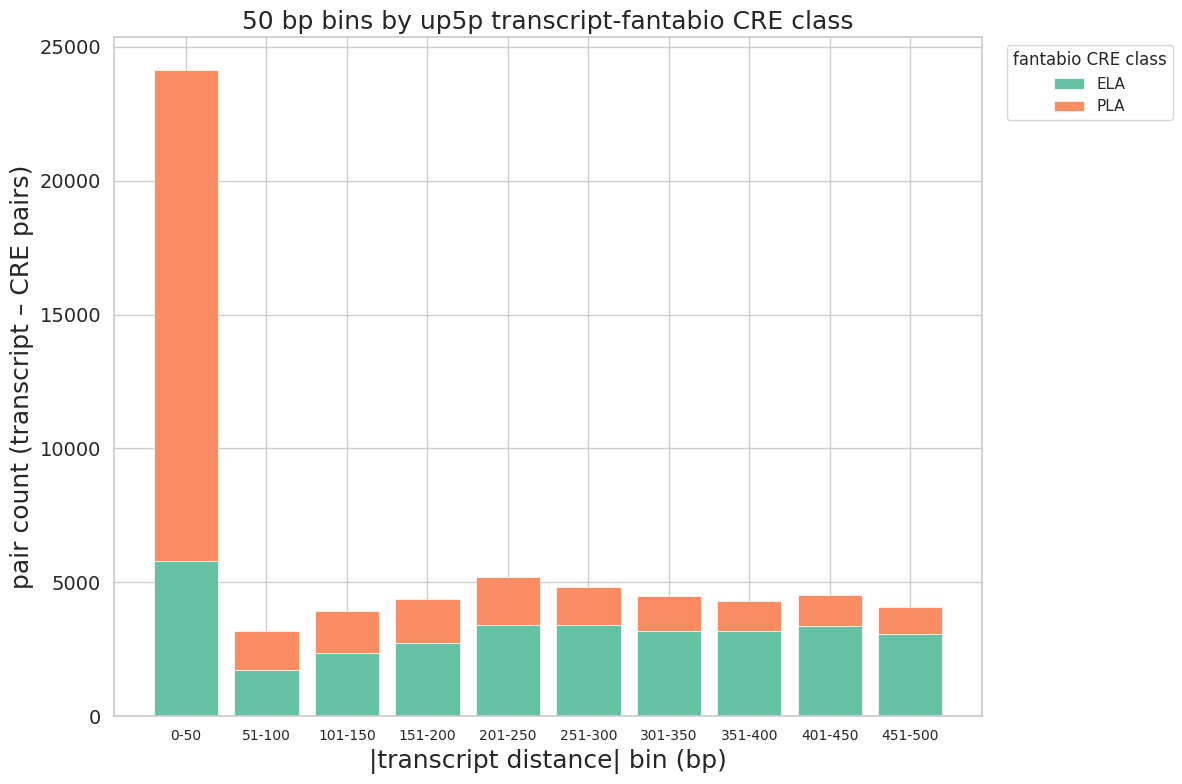

In [16]:
plot_df = up5p_transcript_cre_pairs.to_pandas()

# 10 bins: 0-50, 51-100, 101-200, ..., 451-500
bin_edges = [0, 51, 101, 151, 201, 251, 301, 351, 401, 451, 501]
bin_labels = ["0-50", "51-100", "101-150", "151-200", "201-250", "251-300", "301-350", "351-400", "401-450", "451-500"]

plot_df["distance_bin"] = pd.cut(
    plot_df["transcript_distance_abs"],
    bins=bin_edges,
    labels=bin_labels,
    right=False,
    include_lowest=True,
)

count_df = (
    plot_df.groupby(["distance_bin", "fantabio_cre_class"], observed=True)
    .size()
    .to_frame("count")
    .reset_index()
)

pivot_df = (
    count_df.pivot(index="distance_bin", columns="fantabio_cre_class", values="count")
    .fillna(0)
    .astype(int)
    .reindex(bin_labels)
)

classes = pivot_df.columns.tolist()
palette = sns.color_palette("Set2", n_colors=len(classes))
color_map = dict(zip(classes, palette))

sns.set_theme(style="whitegrid")
fig, ax = plt.subplots(figsize=(12, 8))

bottom = np.zeros(len(pivot_df))
x = np.arange(len(pivot_df.index))

for cls in classes:
    heights = pivot_df[cls].to_numpy()
    ax.bar(
        x,
        heights,
        bottom=bottom,
        label=cls,
        color=color_map[cls],
        edgecolor="white",
        linewidth=0.5,
    )
    bottom += heights

ax.set_xticks(x)
ax.set_xticklabels(pivot_df.index, fontsize=10)
ax.set_xlabel("|transcript distance| bin (bp)", fontsize=18)
ax.set_ylabel("pair count (transcript – CRE pairs)", fontsize=18)
ax.set_title("50 bp bins by up5p transcript-fantabio CRE class", fontsize=18)
ax.legend(title="fantabio CRE class", bbox_to_anchor=(1.02, 1), loc="upper left")
ax.tick_params(axis="y", labelsize=14)

plt.tight_layout()
plt.show()